# FitGym Capstone – Reference Solution (FOR GRADERS ONLY – do not share with learners)
**Business question:** *"Why are members leaving, and can we predict churn?"*

This notebook shows one complete, correct solution, with the numbers graders should expect. Learners may make
different (reasonable) choices – e.g. fill missing visits with the median **or** drop those rows; use a tree **or** logistic regression.
Grade with `Capstone_Rubric.docx`; use these numbers to check that a learner's results are in the right range.

**How to run in Colab:** File → Upload notebook, then click the folder icon and drag in `fitgym.db` (and `members_raw.csv`, `plans.csv` if you want to try the CSV route). Runtime → Run all.

## Step 0 – Imports

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
pd.set_option("display.max_columns", 30)

## Step 1 – SQL: pull members joined with plans
`fitgym.db` holds the **raw** member data (same mess as `members_raw.csv`) plus the `plans` table. A LEFT JOIN keeps every member.
(Equivalent CSV route: `pd.read_csv("members_raw.csv").merge(pd.read_csv("plans.csv"), on="plan_id", how="left")`.)

In [2]:
con = sqlite3.connect("fitgym.db")
query = """
SELECT m.*, p.plan_name, p.duration_months, p.monthly_fee
FROM members AS m
LEFT JOIN plans AS p ON m.plan_id = p.plan_id;
"""
df = pd.read_sql(query, con)

# A quick SQL check a learner might also show: churn label values as stored
print(pd.read_sql("SELECT churned, COUNT(*) AS n FROM members GROUP BY churned ORDER BY n DESC;", con))
con.close()
print(df.shape)
df.head()

  churned     n
0       N  1254
1       Y   230
2      No    34
3     Yes     7
(1525, 14)


,member_id,join_date,age,gender,branch,plan_id,personal_trainer,avg_visits_per_week,classes_attended,last_visit_days_ago,churned,plan_name,duration_months,monthly_fee
0,M0001,2025-04-21,29,Male,Faridabad,PL1,N,4.7,10,2,N,Monthly,1,1500
1,M0002,2024-06-23,25,Female,Gurgaon,PL4,N,4.9,10,0,N,Annual,12,1000
2,M0003,2024-08-02,23,Female,Delhi,PL1,N,2.3,2,67,Y,Monthly,1,1500
3,M0004,2025-07-21,35,Female,noida,PL4,N,1.8,1,28,N,Annual,12,1000
4,M0005,2024-03-06,28,Male,Delhi,PL4,Y,5.6,10,24,N,Annual,12,1000


## Step 2 – Find the mess (inspect before fixing)

In [3]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum()[df.isnull().sum() > 0].to_dict())
print("Branch values:", df["branch"].value_counts().to_dict())
print("Churned values:", df["churned"].value_counts().to_dict())
print("Ages above 100:", (df["age"] > 100).sum(), "->", df.loc[df["age"] > 100, "age"].tolist())

Exact duplicate rows: 25
Missing values: {'avg_visits_per_week': 60}
Branch values: {'Faridabad': 373, 'Delhi': 370, 'Noida': 356, 'Gurgaon': 355, 'DELHI': 24, 'gurgaon': 22, 'noida ': 16, 'Gurugram': 9}
Churned values: {'N': 1254, 'Y': 230, 'No': 34, 'Yes': 7}
Ages above 100: 3 -> [999, 999, 999]


**Expected issues (all five must be found for full cleaning marks, as in `Capstone_Rubric.docx`):**
1. 25 exact duplicate rows
2. Branch spelling variants: `DELHI`, `gurgaon`, `Gurugram`, `noida ` (trailing space)
3. `churned` mixes Y/N with Yes/No
4. 3 impossible ages (999)
5. 60 blank `avg_visits_per_week`

## Step 3 – Clean

In [4]:
clean = df.drop_duplicates().copy()

# Branch: strip spaces, Title Case, then map Gurugram -> Gurgaon (same city)
clean["branch"] = clean["branch"].str.strip().str.title().replace({"Gurugram": "Gurgaon"})

# Churned: make it only Y / N
clean["churned"] = clean["churned"].replace({"Yes": "Y", "No": "N"})

# Age 999 is a data-entry error: set to missing, then fill with the median age
clean.loc[clean["age"] > 100, "age"] = None
age_median = clean["age"].median()
clean["age"] = clean["age"].fillna(age_median)

# Missing visits: fill with the median (choice explained in markdown)
visits_median = clean["avg_visits_per_week"].median()
clean["avg_visits_per_week"] = clean["avg_visits_per_week"].fillna(visits_median)

clean["join_date"] = pd.to_datetime(clean["join_date"])
clean["is_churned"] = (clean["churned"] == "Y").astype(int)

print("Rows after cleaning:", len(clean), "| unique member_id:", clean["member_id"].nunique())
print("Median age used:", age_median, "| median visits used:", visits_median)
print("Branches:", clean["branch"].value_counts().to_dict())
print("Churned:", clean["churned"].value_counts().to_dict())
print("Missing left:", int(clean.isnull().sum().sum()))
print(f"Overall churn rate: {clean['is_churned'].mean():.1%}")

Rows after cleaning: 1500 | unique member_id: 1500
Median age used: 28.0 | median visits used: 3.4
Branches: {'Delhi': 389, 'Gurgaon': 380, 'Noida': 371, 'Faridabad': 360}
Churned: {'N': 1268, 'Y': 232}
Missing left: 0
Overall churn rate: 15.5%


## Step 4 – EDA: who churns?

             members  churned  churn_rate
plan_name                                
Monthly          613      142        23.2
Quarterly        379       54        14.2
Half-Yearly      218       19         8.7
Annual           290       17         5.9


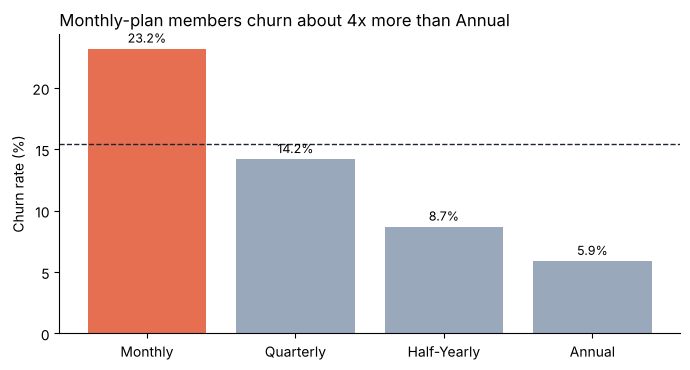

In [5]:
overall = clean["is_churned"].mean()

def churn_table(col):
    t = clean.groupby(col, observed=True).agg(members=("member_id", "count"),
                                              churned=("is_churned", "sum"),
                                              churn_rate=("is_churned", "mean"))
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    return t

def bar(t, title, highlight=None):
    colors = ["#E76F51" if i == highlight else "#9AA8BC" for i in t.index]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.bar(t.index.astype(str), t["churn_rate"], color=colors)
    ax.axhline(overall * 100, color="#1B2433", linestyle="--", linewidth=1)
    for i, v in enumerate(t["churn_rate"]):
        ax.text(i, v + 0.5, f"{v}%", ha="center", fontsize=9)
    ax.set_title(title, loc="left"); ax.set_ylabel("Churn rate (%)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()

by_plan = churn_table("plan_name").loc[["Monthly", "Quarterly", "Half-Yearly", "Annual"]]
print(by_plan)
bar(by_plan, "Monthly-plan members churn about 4x more than Annual", highlight="Monthly")

                  members  churned  churn_rate
personal_trainer                              
N                    1042      192        18.4
Y                     458       40         8.7


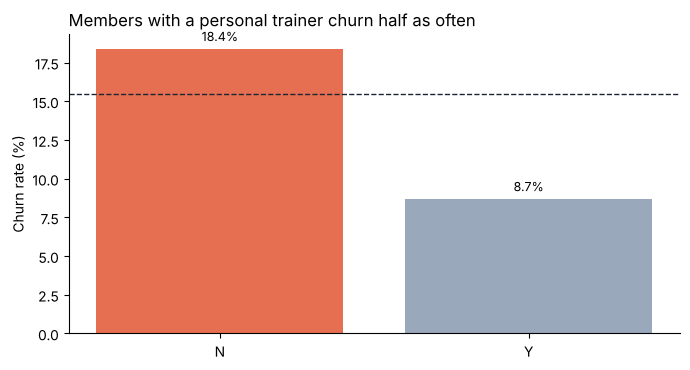

In [6]:
by_trainer = churn_table("personal_trainer")
print(by_trainer)
bar(by_trainer, "Members with a personal trainer churn half as often", highlight="N")

            members  churned  churn_rate
visit_band                              
0-1              69       35        50.7
1-2             160       48        30.0
2-3             355       81        22.8
3-4             469       49        10.4
4+              447       19         4.3


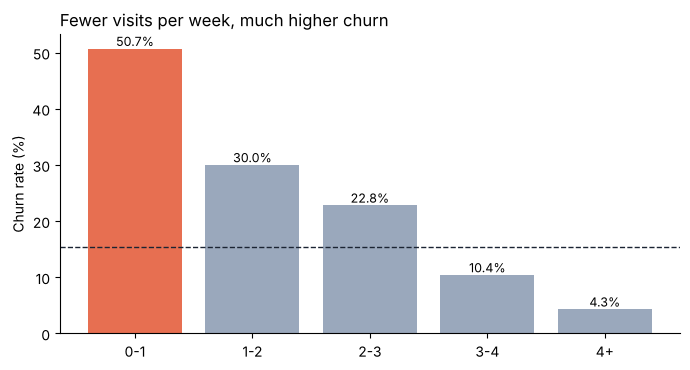

In [7]:
clean["visit_band"] = pd.cut(clean["avg_visits_per_week"], bins=[-0.1, 1, 2, 3, 4, 20],
                             labels=["0-1", "1-2", "2-3", "3-4", "4+"])
by_visits = churn_table("visit_band")
print(by_visits)
bar(by_visits, "Fewer visits per week, much higher churn", highlight="0-1")

                 members  churned  churn_rate
last_visit_band                              
0-7 days             715       85        11.9
8-14                 332       38        11.4
15-30                282       43        15.2
31+ days             171       66        38.6


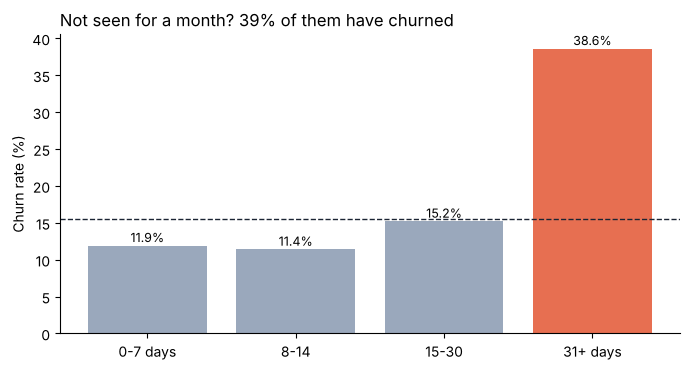

           members  churned  churn_rate
branch                                 
Delhi          389       58        14.9
Faridabad      360       59        16.4
Gurgaon        380       63        16.6
Noida          371       52        14.0


In [8]:
clean["last_visit_band"] = pd.cut(clean["last_visit_days_ago"], bins=[-1, 7, 14, 30, 365],
                                  labels=["0-7 days", "8-14", "15-30", "31+ days"])
by_last = churn_table("last_visit_band")
print(by_last)
bar(by_last, "Not seen for a month? 39% of them have churned", highlight="31+ days")

print(churn_table("branch"))   # branch matters little – a good 'no difference' finding

## Step 5 – Money: monthly fee revenue lost

In [9]:
# Assumption: each churned member would otherwise keep paying their plan's monthly fee
lost_per_month = clean.loc[clean["is_churned"] == 1, "monthly_fee"].sum()
print(f"Monthly fee revenue lost from churned members: ₹{lost_per_month:,.0f} per month")
print(clean[clean["is_churned"] == 1].groupby("plan_name")["monthly_fee"].sum())

Monthly fee revenue lost from churned members: ₹322,050 per month
plan_name
Annual          17000
Half-Yearly     21850
Monthly        213000
Quarterly       70200
Name: monthly_fee, dtype: int64


## Step 6 – Churn model
Features: age, gender, branch, plan, personal trainer, visits per week, classes attended, days since last visit.

**Leakage note for graders:** `last_visit_days_ago` is fine **if** it is measured while the member is still active (a warning sign).
If a learner argues it is recorded after leaving and drops it, that is also good reasoning – reward the argument.
`member_id` and `join_date` should not be used as raw features.

In [10]:
features = ["age", "gender", "branch", "plan_name", "personal_trainer",
            "avg_visits_per_week", "classes_attended", "last_visit_days_ago"]
X = pd.get_dummies(clean[features], drop_first=True, dtype=int)
y = clean["is_churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Baseline 'never churns' accuracy:", round((y_test == 0).mean(), 3))

models = {"Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
          "Logistic regression": LogisticRegression(max_iter=5000, class_weight="balanced")}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(name); print(confusion_matrix(y_test, pred))
    rows.append({"model": name, "accuracy": round(accuracy_score(y_test, pred), 3),
                 "precision": round(precision_score(y_test, pred), 3),
                 "recall": round(recall_score(y_test, pred), 3)})
pd.DataFrame(rows)

Baseline 'never churns' accuracy: 0.847


Decision tree (depth 4)
[[139 115]
 [ 14  32]]


Logistic regression
[[188  66]
 [ 16  30]]


,model,accuracy,precision,recall
0,Decision tree (depth 4),0.570,0.218,0.696
1,Logistic regression,0.727,0.312,0.652


In [11]:
coefs = pd.Series(models["Logistic regression"].coef_[0], index=X.columns).sort_values()
print("Logistic regression coefficients (negative = lowers churn):")
print(coefs.round(3))

Logistic regression coefficients (negative = lowers churn):
personal_trainer_Y      -0.622
avg_visits_per_week     -0.572
gender_Male             -0.036
branch_Noida            -0.026
age                     -0.020
classes_attended         0.002
last_visit_days_ago      0.024
branch_Faridabad         0.081
plan_name_Half-Yearly    0.468
branch_Gurgaon           0.526
plan_name_Quarterly      0.601
plan_name_Monthly        1.570
dtype: float64


## Step 7 – Insights & recommendations (expected content)
1. **Plan length is the biggest driver.** Monthly members churn ~23% vs ~6% for Annual. → Offer a discounted upgrade from Monthly to Quarterly/Annual in month 2.
2. **Engagement predicts leaving.** Members visiting under 1×/week churn ~51%; 4+ visits ~4%. Members not seen for 31+ days churn ~39%. → Trigger a call/WhatsApp when a member hasn't visited for 14 days.
3. **Personal trainers retain members.** With trainer ~9% vs without ~18%. → Offer one free trainer session to new Monthly members.
4. Branch makes little difference (14–17%) – the problem is members' habits and plans, not one location.
- Model: logistic regression catches roughly 2 in 3 churners in the test set (recall ~0.65) – useful to prioritise retention calls.

**Grader check-numbers:** 1,500 rows after cleaning; churn 15.5% (232 members); 4 branches; Monthly ~23.2%; Annual ~5.9%; trainer Y ~8.7% / N ~18.4%.